<a href="https://colab.research.google.com/github/lovnishverma/Python-Getting-Started/blob/main/Sentiment_Analysis_IMDb_Practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical: Sentiment Analysis Using Machine Learning

## Objective

To develop a Machine Learning model that can understand movie reviews and classify them into:

1. Positive Sentiment
2. Negative Sentiment

## Dataset

**IMDb Large Movie Review Dataset (50,000 reviews)**
Source: Stanford University – https://ai.stanford.edu/~amaas/data/sentiment/

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- TF-IDF
- Logistic Regression

**Environment:** Google Colab (no GPU, no Hugging Face and no Kaggle API required)

## Learning Outcomes

After completing this practical, students will understand:

1. What Sentiment Analysis is.
2. How machines process human language.
3. How text is converted into numerical data.
4. What training and testing data mean.
5. How a Machine Learning model learns.
6. How to evaluate a classification model.
7. How to make predictions on new reviews.

> **How to run:** Run the cells one by one from top to bottom (`Shift + Enter`). Do not skip cells.

# 1. Understanding Sentiment Analysis

Imagine a person writes:

> "This movie was absolutely amazing. I loved it!"

A human can easily understand that the person liked the movie.

But how can a computer understand this sentence?

Computers work with numerical data. They cannot directly understand the meaning of English sentences like humans.

**Sentiment Analysis** is a Natural Language Processing (NLP) technique that helps computers identify the emotional tone of text.

For this practical, we will classify reviews into:

| Review | Sentiment |
|---|---|
| The movie was fantastic! | Positive |
| The movie was boring. | Negative |
| I absolutely loved it. | Positive |
| Worst movie ever! | Negative |

## Real-world applications

- Amazon product review analysis
- Customer feedback analysis
- Social media monitoring
- Brand reputation monitoring
- Restaurant review analysis
- Customer satisfaction analysis

## Our task

We will train a Machine Learning model using thousands of already-labelled movie reviews.

The model will learn patterns from these examples and predict whether a **new** review is Positive or Negative.

# Part 1: Setup and Dataset

## Step 1 – Import libraries

Libraries are collections of pre-written code that help us perform tasks without implementing everything from scratch.

In [1]:
import os
import re
import tarfile
import urllib.request

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


**Expected output:**

```
All libraries imported successfully!
```

## Step 2 – Download the IMDb dataset

We are using the famous **IMDb Large Movie Review Dataset**, created for research in sentiment classification.

It contains:

- 25,000 training reviews
- 25,000 testing reviews
- Positive and negative reviews in both sets
- Human-assigned sentiment labels

We download it directly from Stanford University's official dataset page.

> **Note:** The compressed dataset is approximately 80 MB. Downloading and extraction may take a few minutes.

In [2]:
# Official Stanford dataset URL
url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"

# Dataset archive name
archive_name = "aclImdb_v1.tar.gz"

# Download only if it is not already downloaded
if not os.path.exists(archive_name):
    print("Downloading IMDb dataset...")
    urllib.request.urlretrieve(url, archive_name)
    print("Download completed!")
else:
    print("Dataset archive already exists!")

# Extract dataset only if not already extracted
if not os.path.exists("aclImdb"):
    print("Extracting dataset...")
    with tarfile.open(archive_name, "r:gz") as tar:
        tar.extractall(".")
    print("Extraction completed!")
else:
    print("Dataset already extracted!")

Download completed!
Extracting dataset...


/tmp/ipykernel_423/1316830884.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(".")


Extraction completed!


# 2. Understanding the Dataset

After extraction, the dataset looks like this:

```
aclImdb/
│
├── train/
│   ├── pos/
│   ├── neg/
│   └── unsup/
│
└── test/
    ├── pos/
    └── neg/
```

**Explanation:**

| Folder | Meaning |
|---|---|
| `train/pos` | Positive training reviews |
| `train/neg` | Negative training reviews |
| `test/pos` | Positive testing reviews |
| `test/neg` | Negative testing reviews |
| `unsup` | Unlabelled reviews (not used in this practical) |

Each text file contains **one** movie review.

Our task is to read these files and convert them into a Pandas DataFrame.

## Step 3 – Load the dataset

We read every review file and assign a numerical label:

- `1` means **Positive**
- `0` means **Negative**

In [3]:
def load_reviews(folder):
    """Read all positive and negative review files from a folder into a DataFrame."""
    reviews = []
    labels = []

    for sentiment in ["pos", "neg"]:
        path = os.path.join(folder, sentiment)

        for file_name in os.listdir(path):
            if file_name.endswith(".txt"):
                file_path = os.path.join(path, file_name)

                with open(file_path, "r", encoding="utf-8") as file:
                    reviews.append(file.read())

                labels.append(1 if sentiment == "pos" else 0)

    return pd.DataFrame({
        "review": reviews,
        "sentiment": labels
    })


# Load training and testing datasets
train_df = load_reviews("aclImdb/train")
test_df = load_reviews("aclImdb/test")

# The files are read in order (all positive, then all negative).
# Shuffle the rows so positive and negative reviews are mixed.
train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
test_df = test_df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Training dataset loaded:", train_df.shape)
print("Testing dataset loaded:", test_df.shape)

Training dataset loaded: (25000, 2)
Testing dataset loaded: (25000, 2)


**Expected output:**

```
Training dataset loaded: (25000, 2)
Testing dataset loaded: (25000, 2)
```

## Step 4 – Explore the dataset

In [4]:
# Display first five reviews
train_df.head()

,review,sentiment
0,For those who like their murder mysteries busy...,1
1,Most book adaptations are bad but this film le...,0
2,"Some people loved ""The Aristocrats"" and others...",1
3,"Justin goes home to live with his strict, hard...",0
4,"""Laughter is a state of mind"" says the tag, an...",0


| Column | Meaning |
|---|---|
| `review` | Actual movie review |
| `sentiment` | Sentiment label (0 or 1) |

## Step 5 – Check dataset distribution

In [5]:
print("Total reviews:", len(train_df))

print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())

print("\nLabel meanings:")
print("0 = Negative")
print("1 = Positive")

Total reviews: 25000

Sentiment distribution:
sentiment
1    12500
0    12500
Name: count, dtype: int64

Label meanings:
0 = Negative
1 = Positive


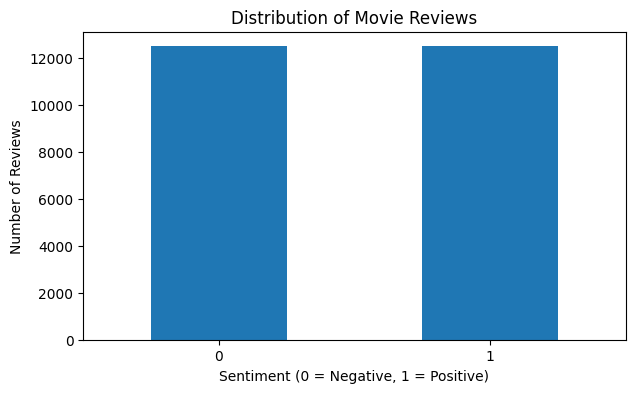

In [6]:
train_df["sentiment"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Distribution of Movie Reviews")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

> **Discussion question:** Why is it important to check whether the dataset contains both positive and negative examples?

## Step 6 – View actual movie reviews

In [7]:
# Display one positive review
print("POSITIVE REVIEW\n")
print(train_df[train_df["sentiment"] == 1]["review"].iloc[0])

print("\n" + "=" * 70)

# Display one negative review
print("\nNEGATIVE REVIEW\n")
print(train_df[train_df["sentiment"] == 0]["review"].iloc[0])

POSITIVE REVIEW

For those who like their murder mysteries busy, this is definitely the one to see, as it is chock full of interesting and suspicious characters, most of them wealthy Long Island socialite types. As the star detective, William Powell is alternately starchy and inspired, behaving at times as if he and his suit went to the cleaners and got pressed together. Mary Astor is very lovely here. <br /><br />Powell had made a career out of playing the lead character, Philo Vance, in a series of movies made at a couple of studios over several years. In-between these films he developed into a somewhat offbeat romantic lead, at times even essaying gentleman gangster roles. Already middle-aged, he was stuck in somewhat of a career rut by the time this one came along. As with so many early talkie stars, it seemed that his time had come and gone, that he was fine for early Depression Prohibition-era films, but that with changing times he was perhaps too mature and dandyish to endure.<b

Discuss how positive and negative words can help a model learn sentiment patterns.

# Part 2: Text Preprocessing

## 3. Why do we preprocess text?

Consider this sentence:

> "I LOVED this movie!!! It was AMAZING."

Computers need text in a consistent format. Text preprocessing helps remove unnecessary formatting and noise.

Common preprocessing operations:

1. Lowercase conversion
2. Removing HTML tags (the IMDb reviews contain `<br />`)
3. Removing unnecessary spaces
4. Removing unwanted symbols when appropriate

For example:

| | Text |
|---|---|
| Original | `I LOVED this movie!!!` |
| Cleaned | `i loved this movie` |

**Important:** We will preserve negation words such as *not*, *never* and *no*, because they can completely change the meaning of a sentence. We also convert contractions such as *didn't* into *did not*, so the negation is not lost when punctuation is removed.

## Step 7 – Create a cleaning function

In [8]:
def clean_text(text):
    # Convert text into lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Keep negation: "didn't" -> "did not", "don't" -> "do not"
    text = re.sub(r"n't\b", " not", text)

    # Keep letters, numbers and spaces
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

## Step 8 – Test preprocessing

In [9]:
sample = "I LOVED this movie!!! It was AMAZING. <br>"

print("Original text:")
print(sample)

print("\nCleaned text:")
print(clean_text(sample))

# Negation check
print("\nNegation example:")
print(clean_text("The movie wasn't good, and I didn't like the ending."))

Original text:
I LOVED this movie!!! It was AMAZING. <br>

Cleaned text:
i loved this movie it was amazing

Negation example:
the movie was not good and i did not like the ending


**Expected output:**

```
Original text:
I LOVED this movie!!! It was AMAZING. <br>

Cleaned text:
i loved this movie it was amazing

Negation example:
the movie was not good and i did not like the ending
```

## Step 9 – Clean the dataset

In [10]:
print("Cleaning training reviews...")
train_df["cleaned_review"] = train_df["review"].apply(clean_text)

print("Cleaning testing reviews...")
test_df["cleaned_review"] = test_df["review"].apply(clean_text)

print("Text preprocessing completed!")

Cleaning training reviews...
Cleaning testing reviews...
Text preprocessing completed!


# Part 3: Convert Text into Numbers

## 4. Why does a computer need numbers?

A Machine Learning algorithm cannot directly understand:

> "This movie was fantastic."

It needs numerical input. One simple way to picture this is:

```
Text:                       "I love this movie"
Numerical representation:   [0.2, 0.5, 0.8, 0.3]
```

The actual numerical values are calculated by a technique called **TF-IDF**.

**TF-IDF** stands for **Term Frequency – Inverse Document Frequency**.

It gives numerical importance to words based on how frequently they appear in a particular document and across the whole collection of documents.

In simple terms:

- Important words in a review can receive **higher** scores.
- Words appearing in almost every review generally receive **lower** importance.

We will use Scikit-learn's `TfidfVectorizer`.

## Step 10 – Understand TF-IDF with a simple example

In [11]:
sample_reviews = [
    "This movie is amazing",
    "This movie is boring",
    "Amazing acting and amazing story"
]

vectorizer_demo = TfidfVectorizer()
sample_matrix = vectorizer_demo.fit_transform(sample_reviews)

# Display vocabulary
print("Vocabulary:")
print(vectorizer_demo.get_feature_names_out())

print("\nNumerical representation:")
print(sample_matrix.toarray().round(2))

Vocabulary:
['acting' 'amazing' 'and' 'boring' 'is' 'movie' 'story' 'this']

Numerical representation:
[[0.   0.5  0.   0.   0.5  0.5  0.   0.5 ]
 [0.   0.   0.   0.6  0.46 0.46 0.   0.46]
 [0.43 0.66 0.43 0.   0.   0.   0.43 0.  ]]


**How to read the output:**

- Each **column** represents a word.
- Each **row** represents a review.
- Each number represents the TF-IDF score of a word in that review.
- **Zero** means the word does not occur in that review.

# 5. Preparing TF-IDF for our dataset

Now we will convert all our IMDb reviews into numerical features.

We will use:

`max_features = 20000` – keep at most 20,000 word features.

`ngram_range = (1, 2)` – the vectorizer considers:

- Single words: *good*, *amazing*, *boring*
- Two-word phrases: *very good*, *not good*, *highly recommended*

**Why is this useful?** Because "good" and "not good" have different meanings.

## Step 11 – Convert the training and testing reviews

We use the original Stanford training and testing folders. This is preferable to randomly splitting all 50,000 reviews because the dataset already provides a separate test set.

In [12]:
X_train = train_df["cleaned_review"]
y_train = train_df["sentiment"]

X_test = test_df["cleaned_review"]
y_test = test_df["sentiment"]

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Learn vocabulary and transform training reviews
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test reviews using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (25000, 20000)
Testing matrix: (25000, 20000)


**Expected output:**

```
Training matrix: (25000, 20000)
Testing matrix: (25000, 20000)
```

The number of columns can be lower than 20,000 if fewer words or phrases pass the filters.

> **Important teaching point:** We fit TF-IDF **only on the training data**. We never allow the test data to influence the vocabulary or feature weights.

# Part 4: Train the Machine Learning Model

## 6. Understanding Logistic Regression

Logistic Regression is a Machine Learning algorithm used for **classification**.

Our problem has two classes:

- `0` = Negative
- `1` = Positive

The algorithm learns patterns from labelled movie reviews. For example, it may learn that words and phrases such as *wonderful*, *excellent*, *amazing*, *loved* are often associated with positive reviews.

Similarly, *boring*, *terrible*, *worst*, *disappointing* may be associated with negative reviews.

These are only illustrative examples. The model learns its actual patterns from the training data.

During training, the model learns numerical **weights** for features and uses them to estimate the probability of each class.

## Step 12 – Train the model

In [13]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Training the model...")
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Training the model...
Model training completed successfully!


## What happened during training?

We provided the model with:

- **Input:** Numerical representations of 25,000 reviews.
- **Output:** Correct sentiment labels for those reviews.

The model learned the relationship between the numerical features and the sentiment labels.

The trained model can now predict sentiment for new reviews.

This is called **Supervised Learning** because we trained it using examples with known answers (labels).

### Optional: What did the model learn?

Let us look at the words and phrases the model considers the strongest signals.

In [14]:
feature_names = np.array(tfidf.get_feature_names_out())
weights = model.coef_[0]

sorted_idx = np.argsort(weights)

print("Top 15 NEGATIVE words/phrases:")
print(feature_names[sorted_idx[:15]])

print("\nTop 15 POSITIVE words/phrases:")
print(feature_names[sorted_idx[-15:][::-1]])

Top 15 NEGATIVE words/phrases:
['bad' 'worst' 'awful' 'the worst' 'boring' 'poor' 'waste' 'terrible'
 'nothing' 'worse' 'dull' 'no' 'poorly' 'horrible' 'stupid']

Top 15 POSITIVE words/phrases:
['great' 'excellent' 'perfect' 'wonderful' 'amazing' 'the best' 'best'
 'today' 'fun' 'loved' 'love' 'superb' 'favorite' 'brilliant' 'enjoyed']


# Part 5: Test and Evaluate the Model

## Step 13 – Make predictions

The model has never seen the test reviews. Let us see how it performs on them.

In [15]:
y_pred = model.predict(X_test_tfidf)

print("First 10 predictions:")
print(y_pred[:10])

print("\nActual labels:")
print(y_test.iloc[:10].values)

First 10 predictions:
[1 0 1 1 0 1 1 0 1 1]

Actual labels:
[1 0 1 0 0 1 1 0 1 1]


## Step 14 – Calculate accuracy

In [16]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 89.97 %


**Teaching explanation:**

Accuracy tells us how many predictions the model got correct out of all test examples.

For example, 85% accuracy means that the model correctly classified approximately 85 out of every 100 test reviews.

The actual accuracy depends on the model settings and preprocessing. With this setup you should typically see a value in the high 80s.

## Step 15 – Classification report

In [17]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

              precision    recall  f1-score   support

    Negative       0.90      0.89      0.90     12500
    Positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



| Metric | Simple meaning |
|---|---|
| Precision | When the model predicts a class, how often is it correct? |
| Recall | How many actual examples of a class did it find? |
| F1-score | Balance between precision and recall |
| Support | Number of actual examples in that class |

## Step 16 – Confusion matrix

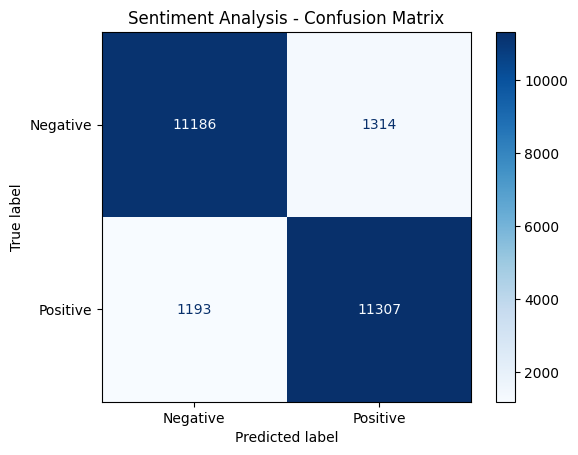

In [18]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Sentiment Analysis - Confusion Matrix")
plt.show()

The four possible outcomes:

- **True Negative:** Negative review correctly predicted as negative.
- **True Positive:** Positive review correctly predicted as positive.
- **False Positive:** Negative review incorrectly predicted as positive.
- **False Negative:** Positive review incorrectly predicted as negative.

> **Discussion question:** Why is accuracy alone not always enough to evaluate a model?

# Part 6: Test with Your Own Reviews

## Step 17 – Build a prediction function

This is the most important interactive part of the practical. Students can enter any movie review and see the model's prediction.

In [19]:
def predict_sentiment(review):
    # Clean the input review
    cleaned = clean_text(review)

    # Convert text into numerical features
    review_vector = tfidf.transform([cleaned])

    # Predict sentiment
    prediction = model.predict(review_vector)[0]

    # Get probabilities
    probabilities = model.predict_proba(review_vector)[0]

    # Display result
    if prediction == 1:
        sentiment = "POSITIVE 😊"
    else:
        sentiment = "NEGATIVE 😞"

    confidence = probabilities[prediction] * 100

    print("\nReview:")
    print(review)

    print("\nPredicted Sentiment:")
    print(sentiment)

    print("\nModel Confidence:")
    print(f"{confidence:.2f}%")

    print("-" * 60)

## Step 18 – Test five example reviews

In [20]:
reviews = [
    "This movie was absolutely amazing. I loved every moment!",
    "The acting was terrible and the story was boring.",
    "A wonderful film with excellent performances.",
    "This is the worst movie I have ever watched.",
    "The movie was okay, nothing special."
]

for review in reviews:
    predict_sentiment(review)


Review:
This movie was absolutely amazing. I loved every moment!

Predicted Sentiment:
POSITIVE 😊

Model Confidence:
89.49%
------------------------------------------------------------

Review:
The acting was terrible and the story was boring.

Predicted Sentiment:
NEGATIVE 😞

Model Confidence:
96.02%
------------------------------------------------------------

Review:
A wonderful film with excellent performances.

Predicted Sentiment:
POSITIVE 😊

Model Confidence:
99.24%
------------------------------------------------------------

Review:
This is the worst movie I have ever watched.

Predicted Sentiment:
NEGATIVE 😞

Model Confidence:
97.82%
------------------------------------------------------------

Review:
The movie was okay, nothing special.

Predicted Sentiment:
NEGATIVE 😞

Model Confidence:
91.72%
------------------------------------------------------------


## Step 19 – Enter your own review

Try examples such as:

- "The movie was brilliant and entertaining."
- "I wasted three hours watching this terrible film."
- "The acting was excellent, but the ending was disappointing."

Discuss whether the model's prediction matches the intended meaning.

In [21]:
my_review = input("Enter your movie review: ")
predict_sentiment(my_review)

Enter your movie review: movie was silly

Review:
movie was silly

Predicted Sentiment:
NEGATIVE 😞

Model Confidence:
90.59%
------------------------------------------------------------


# Part 7: Understand the Complete Workflow

## Machine Learning pipeline

We have completed the following pipeline:

```
            IMDb Dataset
                  |
                  v
          Load Movie Reviews
                  |
                  v
          Explore the Dataset
                  |
                  v
          Text Preprocessing
                  |
                  v
             TF-IDF
       (Text to Numerical Data)
                  |
                  v
         Logistic Regression
                  |
                  v
             Training
                  |
                  v
          Model Prediction
                  |
                  v
             Evaluation
                  |
                  v
         Positive / Negative
```

This is a basic **Natural Language Processing (NLP)** and **Supervised Machine Learning** project.

### Combining the steps in a single Pipeline

Scikit-learn can combine text conversion and model training into one object. This is an alternative way of doing what we did step by step above.

In [22]:
from sklearn.pipeline import Pipeline

# Create a combined pipeline for future use.
# It performs TF-IDF transformation followed by classification.
sentiment_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Complete pipeline created!")

# Optional: train and evaluate the pipeline in one go
# sentiment_pipeline.fit(X_train, y_train)
# print("Pipeline accuracy:", sentiment_pipeline.score(X_test, y_test))

Complete pipeline created!


# Part 8: Student Exercises

## Exercise 1: Understand the dataset

1. How many training reviews are available?
2. How many testing reviews are available?
3. What does label 0 represent?
4. What does label 1 represent?

## Exercise 2: Experiment with preprocessing

Try changing the cleaning function. Observe what happens when you remove punctuation or convert text to lowercase.

Why should we preserve words such as "not"?

## Exercise 3: Experiment with TF-IDF

Change `max_features = 20000`. Try `max_features = 5000`, then `max_features = 30000`.

Retrain the model and compare the results.

## Exercise 4: Experiment with algorithms

Try replacing Logistic Regression with:

```python
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
```

Compare the accuracy and classification report. Remember to fit the model again on the training features.

## Exercise 5: Test difficult reviews

Try sentences containing:

- Sarcasm
- Mixed opinions
- Negation
- Very short reviews

Observe where the model makes mistakes.

# Mini Project: Build Your Own Sentiment Analyzer

Now that you understand the complete workflow, try creating a sentiment analysis system for another domain.

Possible topics:

1. Amazon Product Reviews
2. Restaurant Reviews
3. Hotel Reviews
4. Customer Feedback
5. Mobile App Reviews

**Requirements:**

1. Find a labelled dataset.
2. Load the dataset using Pandas.
3. Explore positive and negative examples.
4. Clean the text.
5. Apply TF-IDF.
6. Train a Machine Learning model.
7. Evaluate the model.
8. Test new examples.

## Final Questions

1. Why can't Logistic Regression directly process raw text?
2. What is TF-IDF?
3. Why do we divide data into training and testing sets?
4. What is the difference between training and prediction?
5. Can a model understand sarcasm?
6. What are the limitations of traditional Machine Learning approaches for understanding human language?

# Conclusion

Congratulations! You have successfully developed a Sentiment Analysis model using Machine Learning and Natural Language Processing.

In this practical, you learned:

- How to obtain a real-world dataset.
- How to explore movie reviews.
- How to perform text preprocessing.
- How to convert text into numerical features using TF-IDF.
- How to train Logistic Regression.
- How to evaluate a classification model.
- How to predict sentiment for new reviews.

## What should you learn next?

1. Naive Bayes for text classification.
2. Word2Vec and Word Embeddings.
3. Recurrent Neural Networks (RNN).
4. Long Short-Term Memory (LSTM).
5. Transformers and BERT.

This practical provides the foundation for understanding more advanced NLP and Deep Learning models.

---

## Instructor notes

**Important point to explain to students:** We are not building an AI that understands emotions exactly like a human. We are building a supervised machine-learning classifier that learns statistical patterns from labelled text. This distinction helps students understand the foundation before moving to LSTM, BERT and modern LLMs.

**Suggested time: 2–3 hours**

| Topic | Suggested time |
|---|---|
| Introduction and dataset | 25 min |
| Text preprocessing | 25 min |
| TF-IDF | 30 min |
| Model training | 25 min |
| Evaluation and predictions | 25 min |
| Student exercises | 30 min |